In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
%matplotlib inline

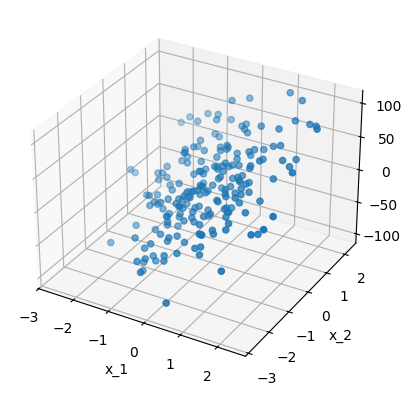

In [2]:
np.random.seed(0)
X, Y = make_regression(n_samples=200, n_features=2, noise=10)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], Y)
ax.set_xlabel('x_1')
ax.set_ylabel('x_2')
ax.set_zlabel('y')
plt.show()

In [3]:
Y = Y.reshape(Y.shape[0], 1)
X = np.hstack((X, np.ones((X.shape[0], 1))))
print(X.shape, Y.shape)

(200, 3) (200, 1)


In [4]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)

(160, 3) (40, 3) (160, 1) (40, 1)


In [5]:
np.random.seed(1)
theta_initial = np.random.randn(X_train.shape[1], 1)
theta_initial

array([[ 1.62434536],
       [-0.61175641],
       [-0.52817175]])

In [6]:
def model(X, theta):
    return X.dot(theta)

In [7]:
def gradient_descent(X, y, theta, learning_rate, n_iterations):
    cost_history = np.zeros(n_iterations)
    for i in range(n_iterations):
        theta = theta - learning_rate * grad(X, y, theta)
        cost_history[i] = cost_function(X, y, theta)
    return theta, cost_history

In [8]:
def grad(X, y, theta):
    m = len(y)
    return 1/m * X.T.dot(model(X, theta) - y)

In [9]:
def cost_function(X, y, theta):
    m = len(y)
    return 1/(2*m) * np.sum((model(X, theta) - y)**2)

In [10]:
cost_function(X_train, Y_train, theta_initial)

np.float64(695.0935534700354)

In [11]:
n_iterations = 1000
learning_rate = 0.01
theta_final, cost_history = gradient_descent(X_train, Y_train, theta_initial, learning_rate, n_iterations)
predictions = model(X_test, theta_final)
print(theta_final)

[[19.96407851]
 [33.53758946]
 [-1.24252878]]


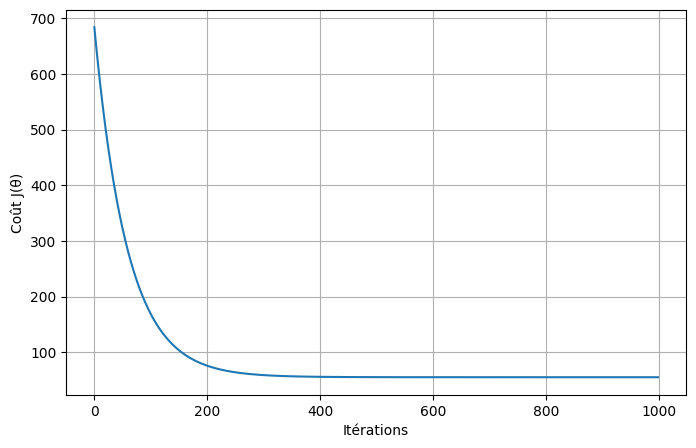

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(range(n_iterations), cost_history)
plt.xlabel('Itérations')
plt.ylabel('Coût J(θ)')
plt.grid(True)
plt.show()

In [13]:
def coef_determination(y, pred):
    u = ((y - pred)**2).sum()
    v = ((y - y.mean())**2).sum()
    return 1 - u/v

coef_determination(Y_test, predictions)

np.float64(0.9570657437957424)